# Betting Against Beta — Part A: Section 1, Betas With Information Available at the Time

**Idea in four steps**
1. For every stock and month end *t*, regress the stock's excess return on the market's excess return over the trailing *W* months in which the stock has a return. The slope is the beta.
2. At month end *t*, rank the eligible stocks by beta and split them into 10 equal-count groups (decile 1 = lowest beta, 10 = highest).
3. Hold each decile, value-weighted by market cap at *t*, during month *t+1*.
4. Summarize each decile: pre- and post-ranking beta, mean excess return, alpha, Treynor and information ratios.

**No look-ahead:** the beta used at *t* contains data only through *t*; the return measured is *t+1*.

**Data and conventions (from the brief).** We use the supplied **delisting-adjusted returns** (`ret`). Excess returns subtract Ken French's `RF`, and the market is `Mkt-RF`. Eligible stocks at *t* have a beta, positive market cap, a price, and no delisting code (`dlstcd`) at *t*. A held stock with a missing return in *t+1* earns a total return of zero (excess −RF) and keeps its weight. Months with a missing return are omitted when estimating betas. Means are annualized ×12 and volatilities ×√12; alphas are annualized with plain OLS t-statistics. **Every full-sample exhibit runs from 1966-01 to 2026-09.**

*Revision notes.* Compared with the first version, this notebook uses the brief's windows (60 months with at least 36, and 36 with at least 24) instead of 6m/1y/2y/5y/10y. The market is FF `Mkt-RF` with `RF`, replacing a CRSP proxy with RF = 0. It applies the eligibility screen and the missing-return rule, and adds the missing 1.1–1.3 outputs. The shared functions are in `bab_core.py`, so Sections 2–6 use exactly these betas and deciles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import bab_core as bc

panel = bc.load_panel()
mkt = panel.mkt
print(f"{panel.ret.shape[1]:,} stocks, {panel.ret.shape[0]} months, "
      f"{panel.ret.index[0]:%Y-%m} to {panel.ret.index[-1]:%Y-%m}")


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

26,519 stocks, 765 months, 1963-01 to 2026-09


## 1.1 Trailing 60-month betas

Beta at month end *t* from months *t*−59 to *t*, using only months with a return, requiring at least 36. Below: each December from 1973, the number of eligible stocks with an estimate and the 10th, 50th and 90th percentiles of the estimates.

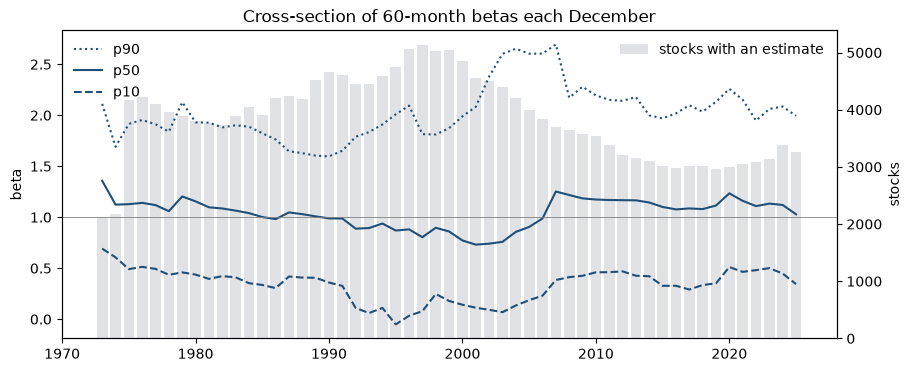

December,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
stocks,2106.00,2178.00,4173.00,4224.00,4102.00,3954.00,3896.00,3795.00,3773.00,3735.00,3889.00,4039.00,3913.00,4201.00,4233.00,4186.00,4520.00,4656.00,4603.00,4448.00,4446.00,4581.00,4740.00,5069.00,5131.00,5033.00,5039.00,4846.00,4557.00,4496.00,4404.00,4209.00,3993.00,3835.00,3701.00,3638.00,3573.00,3542.00,3375.00,3216.00,3149.00,3102.00,3018.00,2983.00,3020.00,3009.00,2968.00,2990.00,3044.00,3078.00,3145.00,3380.00,3265.00
p10,0.69,0.61,0.49,0.51,0.49,0.44,0.46,0.44,0.40,0.42,0.41,0.35,0.34,0.30,0.42,0.41,0.41,0.36,0.33,0.11,0.06,0.11,-0.05,0.03,0.08,0.25,0.18,0.14,0.11,0.09,0.07,0.13,0.19,0.23,0.38,0.41,0.43,0.46,0.46,0.47,0.43,0.42,0.33,0.33,0.29,0.34,0.35,0.51,0.46,0.48,0.50,0.45,0.34
p50,1.36,1.12,1.13,1.14,1.12,1.06,1.20,1.16,1.10,1.09,1.06,1.04,1.00,0.98,1.05,1.03,1.01,0.99,0.99,0.89,0.89,0.94,0.87,0.88,0.80,0.90,0.86,0.77,0.73,0.74,0.76,0.86,0.90,0.99,1.25,1.22,1.18,1.17,1.17,1.17,1.17,1.14,1.10,1.08,1.09,1.08,1.11,1.23,1.16,1.11,1.13,1.12,1.03
p90,2.11,1.69,1.92,1.95,1.91,1.84,2.13,1.93,1.93,1.88,1.90,1.89,1.82,1.76,1.65,1.63,1.60,1.60,1.65,1.79,1.83,1.91,2.01,2.09,1.81,1.81,1.87,1.99,2.08,2.38,2.60,2.65,2.60,2.60,2.69,2.17,2.28,2.19,2.15,2.14,2.18,2.00,1.97,2.02,2.10,2.03,2.13,2.26,2.15,1.95,2.06,2.09,1.99


In [2]:
beta60 = bc.rolling_beta(panel.ex, mkt, 60, 36)
beta36 = bc.rolling_beta(panel.ex, mkt, 36, 24)      # used in 1.3
eligible = panel.eligible

est = beta60.where(eligible)
dec = est[(est.index.month == 12) & (est.index.year >= 1973)]
t11 = pd.DataFrame({"stocks": dec.notna().sum(axis=1),
                    "p10": dec.quantile(0.10, axis=1),
                    "p50": dec.quantile(0.50, axis=1),
                    "p90": dec.quantile(0.90, axis=1)})
t11.index = t11.index.year.rename("December")

fig, ax = plt.subplots(figsize=(10, 4))
for c, style in [("p90", ":"), ("p50", "-"), ("p10", "--")]:
    ax.plot(t11.index, t11[c], ls=style, color="#1f4e79", label=c)
ax.axhline(1, color="grey", lw=0.6)
ax.set(title="Cross-section of 60-month betas each December", ylabel="beta")
ax2 = ax.twinx()
ax2.bar(t11.index, t11["stocks"], color="#8a8f98", alpha=0.25, label="stocks with an estimate")
ax2.set_ylabel("stocks"); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.legend(loc="upper left", frameon=False); ax2.legend(loc="upper right", frameon=False)
plt.show()
show(t11.T, precision=2)

The count doubles between 1974 and 1975 because Nasdaq stocks, which enter in December 1972, reach 36 months of returns. The median beta stays near one (0.73–1.36), but the spread is wide: the 10th percentile runs from about −0.05 to 0.69 and the 90th from 1.6 to 2.7. The 10th percentile sits near zero from 1992 to 2003, and the 90th–10th range is widest in 2002–2007 (about 2.3–2.5). With about 3,900 stocks a year and standard errors near 0.26 on sixty months, part of that spread is estimation noise, which is what 1.3 measures.

## 1.2 Beta-decile portfolios

From 1965-12, each month end: rank the eligible stocks on the 60-month beta, form ten equal-count groups (a stock at a breakpoint goes to the lower group), and hold each value-weighted for one month. **Pre-ranking beta** is the portfolio-weighted average of the stock betas used to sort, averaged over months. **Post-ranking beta** is the slope of the decile's realized excess return on `Mkt-RF` over the holding months. Treynor ratio = mean excess return / post-ranking beta. Information ratio = alpha / residual volatility (both annualized).

In [3]:
dec_ex, dec_pre, dec_n = bc.decile_sort(beta60, panel)


def decile_table(ex, pre):
    m = mkt.reindex(ex.index)
    rows = {}
    for g in ex:
        alpha, beta, t_alpha, _, resid, _ = bc.ols(ex[g], m)
        mean = 12 * ex[g].mean()
        rows[g] = {"pre_beta": pre[g].mean(), "post_beta": beta, "mean_excess": mean,
                   "alpha": 12 * alpha, "t_alpha": t_alpha, "treynor": mean / beta,
                   "info_ratio": 12 * alpha / (np.sqrt(12) * resid.std(ddof=2))}
    return pd.DataFrame(rows).T.rename_axis("decile")


t12 = decile_table(dec_ex, dec_pre)
premium = 12 * mkt.reindex(dec_ex.index).mean()
print(f"Holding months {dec_ex.index[0]:%Y-%m} to {dec_ex.index[-1]:%Y-%m} ({len(dec_ex)}); "
      f"stocks per decile {dec_n.min().min()}-{dec_n.max().max()}; market premium {premium:.2%}, "
      f"market Treynor ratio {premium:.2%}")
show(t12, pct=["mean_excess", "alpha", "treynor"])

Holding months 1966-01 to 2026-09 (729); stocks per decile 171-519; market premium 7.03%, market Treynor ratio 7.03%


,pre_beta,post_beta,mean_excess,alpha,t_alpha,treynor,info_ratio
decile,,,,,,,
1,0.225,0.536,6.06%,2.29%,1.848,11.30%,0.239
2,0.492,0.646,6.25%,1.71%,1.754,9.67%,0.227
3,0.680,0.758,7.81%,2.49%,2.766,10.31%,0.358
4,0.837,0.868,7.18%,1.08%,1.309,8.27%,0.169
5,0.991,0.979,7.93%,1.05%,1.332,8.10%,0.172
6,1.144,1.073,8.28%,0.74%,0.908,7.71%,0.117
7,1.314,1.195,6.69%,-1.71%,-2.061,5.59%,-0.267
8,1.520,1.299,7.25%,-1.87%,-1.909,5.58%,-0.247
9,1.811,1.493,8.56%,-1.92%,-1.301,5.74%,-0.168


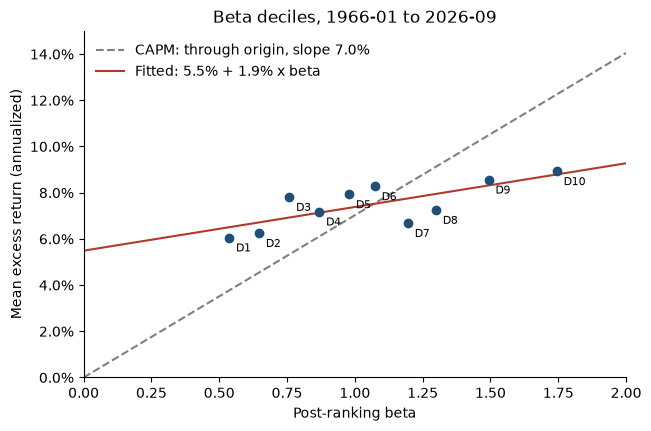

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(t12["post_beta"], t12["mean_excess"], color="#1f4e79", zorder=3)
for g, r in t12.iterrows():
    ax.annotate(f"D{g}", (r["post_beta"], r["mean_excess"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
grid = np.linspace(0, 2, 50)
a, b, *_ = bc.ols(t12["mean_excess"], t12["post_beta"])
ax.plot(grid, premium * grid, color="grey", ls="--", label=f"CAPM: through origin, slope {premium:.1%}")
ax.plot(grid, a + b * grid, color="#b03a2e", label=f"Fitted: {a:.1%} + {b:.1%} x beta")
ax.set(xlabel="Post-ranking beta", ylabel="Mean excess return (annualized)",
       title="Beta deciles, 1966-01 to 2026-09", xlim=(0, 2), ylim=(0, 0.15))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

The line is much flatter than the CAPM's. Post-ranking betas run from 0.54 to 1.74, but mean excess returns rise only from 6.1% to 8.9%, where the CAPM predicts 3.8% and 12.3%. Alphas fall from about +2% in the low deciles to −3% in D10, and the Treynor ratio falls from 11% to 5%. Pre-ranking betas (0.23 to 2.42) are far more dispersed than post-ranking betas, the first sign of estimation error. Section 2 tests this formally.

## 1.3 A 36-month window

Second beta from the trailing 36 months, requiring at least 24. Over the formation dates for holding months 1966-01 to 2026-09, we report:
- the cross-sectional Spearman correlation between the two estimates (stocks with both), averaged over dates;
- the share of stocks below the 60-month median that are also below the 36-month median;
- for deciles formed on each estimator, the slope of post- on pre-ranking decile betas.

In [5]:
dates = dec_ex.index - pd.offsets.MonthEnd(1)          # formation dates
b60, b36 = beta60.where(eligible).loc[dates], beta36.where(eligible).loc[dates]
spearman, same_side, n_both = [], [], []
for t in dates:
    both = b60.loc[t].notna() & b36.loc[t].notna()
    x, y = b60.loc[t, both], b36.loc[t, both]
    spearman.append(stats.spearmanr(x, y).statistic)
    below = x < x.median()
    same_side.append((y[below] < y.median()).mean())
    n_both.append(both.sum())

ex36, pre36, _ = bc.decile_sort(beta36, panel)
t13_deciles = decile_table(ex36, pre36)
slope = lambda t: bc.ols(t["post_beta"], t["pre_beta"])[1]

t13 = pd.Series({
    "avg Spearman correlation, 36m vs 60m": np.mean(spearman),
    "share below 60m median also below 36m median": np.mean(same_side),
    "avg stocks with both estimates": np.mean(n_both),
    "post-on-pre decile slope, 60m": slope(t12),
    "post-on-pre decile slope, 36m": slope(t13_deciles),
}).to_frame("value")
show(t13)
show(pd.DataFrame({"pre 60m": t12["pre_beta"], "post 60m": t12["post_beta"],
                   "pre 36m": t13_deciles["pre_beta"], "post 36m": t13_deciles["post_beta"]}))

,value
"avg Spearman correlation, 36m vs 60m",0.868
share below 60m median also below 36m median,0.861
avg stocks with both estimates,3584.228
"post-on-pre decile slope, 60m",0.583
"post-on-pre decile slope, 36m",0.497


,pre 60m,post 60m,pre 36m,post 36m
decile,,,,
1,0.225,0.536,0.082,0.599
2,0.492,0.646,0.407,0.654
3,0.680,0.758,0.625,0.755
4,0.837,0.868,0.805,0.860
5,0.991,0.979,0.978,0.979
6,1.144,1.073,1.151,1.078
7,1.314,1.195,1.344,1.166
8,1.520,1.299,1.585,1.308
9,1.811,1.493,1.918,1.486


**What the windows say about measurement error.** The two estimates rank stocks similarly (Spearman 0.87), and 86% of the stocks below one median are below the other. Still, the post-on-pre slope is 0.58 for the 60-month estimator but only 0.50 for the 36-month one. Pre-ranking betas from 36 months spread further (0.08 to 2.64) while post-ranking betas barely change (0.60 to 1.78), so the extra spread is noise. With $\hat\beta = \beta + e$ the slope is $\text{var}(\beta)/(\text{var}(\beta)+\text{var}(e))$. That puts the error variance at about 0.7 of the true cross-sectional variance on 60 months and about 1.0 on 36 months, a ratio of 1.4. If betas were constant, the ratio would be 60/36 ≈ 1.7. The smaller ratio is consistent with true betas drifting over time, so a longer window gains precision but also uses staler information.

**Does the evidence argue for a different window?** No. The shorter window is noisier: it sorts worse and would set leverage on more exaggerated betas. The appendix shows the slope keeps falling at 24 and 12 months (0.41 and 0.27). D1's alpha also shrinks from +2.3% at 60 months to about zero at 24–36 months and −2.8% at 12 months: a noisy sort fills the low-beta decile with stocks whose true betas are not low. The 60-month window, with shrinkage toward one, is the better default. A longer window is a Section 4 question, because the gain in precision is partly offset by staleness.

## Appendix: other windows

Value-weighted deciles over the same holding months (1966-01 to 2026-09) for shorter windows. This extends the comparison in the first version of this notebook, now with the brief's conventions.

In [6]:
windows = {"12m (min 12)": (12, 12), "24m (min 24)": (24, 24), "36m (min 24)": (36, 24), "60m (min 36)": (60, 36)}
rows = {}
for name, (w, k) in windows.items():
    ex, pre, _ = bc.decile_sort(bc.rolling_beta(panel.ex, mkt, w, k), panel)
    t = decile_table(ex, pre)
    rows[name] = {"post-on-pre slope": slope(t), "pre D1": t.loc[1, "pre_beta"], "pre D10": t.loc[10, "pre_beta"],
                  "post D1": t.loc[1, "post_beta"], "post D10": t.loc[10, "post_beta"],
                  "alpha D1": t.loc[1, "alpha"], "alpha D10": t.loc[10, "alpha"], "months": len(ex)}
show(pd.DataFrame(rows).T.astype({"months": int}), pct=["alpha D1", "alpha D10"])

,post-on-pre slope,pre D1,pre D10,post D1,post D10,alpha D1,alpha D10,months
12m (min 12),0.267,-0.638,3.392,0.820,1.741,-2.76%,-2.72%,729
24m (min 24),0.411,-0.087,2.832,0.677,1.752,-0.54%,-2.80%,729
36m (min 24),0.497,0.082,2.636,0.599,1.776,0.02%,-2.82%,729
60m (min 36),0.583,0.225,2.415,0.536,1.744,2.29%,-3.32%,729
